# Лабораторная работа 2. Рекомендательные системы

**Датасет:** [KuaiRec](https://github.com/chongminggao/KuaiRec) (Kuaishou, CIKM 2022). Открытый полностью наблюдаемый датасет коротких видео: у каждого пользователя зафиксировано, какие видео ему показывали и какие он посмотрел. Лицензия CC BY-SA 4.0, источник [Zenodo, запись 18164998](https://zenodo.org/records/18164998). Запрещённые источники, Kaggle и MovieLens, не используются.

**Постановка.** Выбрать датасет, провести разведочный анализ с оценкой качества данных, выделить целевую переменную, реализовать не менее трёх методов формирования рекомендации из разных семейств, вычислить на тестовой выборке не менее четырёх метрик качества, включая метрику ранжирования и специфичную для рекомендательных систем метрику, сравнить методы, дать интерпретацию и предложить улучшения.

**Исходные данные и подготовленная выборка.** В оригинальном датасете таблица `big_matrix.csv` содержит 12 530 806 записей о показах коротких видео 7 176 пользователям по 10 728 видео за период с 23 июня по 9 сентября 2020 года. Для лабораторной работы подготовлена выборка релевантных взаимодействий: 1 200 самых популярных видео и 1 500 случайно выбранных пользователей, что даёт 412 422 взаимодействия. Логика отбора описана в ячейке 4, объём выбран так, чтобы все методы обучались и считались на ноутбуке за разумное время.

## Ячейка 1. Подготовка окрунения и загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import seaborn as sns
from sklearn.preprocessing import normalize

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

SEED = 42
DATA_PATH = "kuairec_interactions.csv"

try:
    interactions = pd.read_csv(DATA_PATH)
except FileNotFoundError as error:
    raise FileNotFoundError(
        f"Файл {DATA_PATH} не найден в рабочей директории ноутбука"
    ) from error

print(f"Загружено взаимодействий: {len(interactions)}")
print(f"Пользователей: {interactions['user_idx'].nunique()}")
print(f"Видео: {interactions['item_id'].nunique()}")
interactions.head()

Загружено взаимодействий: 412422
Пользователей: 1500
Видео: 1200


,user_idx,item_id,watch_ratio,timestamp,date
0,0,250,1.182899,1593903045,20200705
1,0,7,1.810714,1593904481,20200705
2,0,630,1.598990,1593904667,20200705
3,0,248,1.404445,1593905869,20200705
4,0,435,1.568888,1593906134,20200705


### Описание полей

| Поле | Тип | Смысл |
| --- | --- | --- |
| `user_idx` | int32 | идентификатор пользователя, перенумерован без пропусков |
| `item_id` | int32 | идентификатор видео, перенумерован без пропусков |
| `watch_ratio` | float32 | отношение длительности просмотра к длительности видео |
| `timestamp` | int64 | момент начала просмотра, unix-время в секундах |
| `date` | int32 | дата просмотра в формате `ГГГГММДД` |

Каждая строка означает, что пользователю было показано видео и он его посмотрел с коэффициентом `watch_ratio`. Значение больше единицы означает пересмотр: пользователь досмотрел видео до конца и запустил его снова.

In [1]:
print(interactions.dtypes)
print()
print(interactions.describe().T)
print()
print("Пропуски по столбцам:")
print(interactions.isna().sum().to_string())
print()
print("Полные дубликаты строк:", int(interactions.duplicated().sum()))
print("Дубликаты пар (пользователь, видео):", int(interactions.duplicated(["user_idx", "item_id"]).sum()))

user_idx         int64
item_id          int64
watch_ratio    float64
timestamp        int64
date             int64
dtype: object

                count          mean           std           min           25%           50%           75%           max
user_idx     412422.0  7.642731e+02  4.307732e+02  0.000000e+00  3.930000e+02  7.730000e+02  1.131000e+03  1.499000e+03
item_id      412422.0  6.041431e+02  3.473912e+02  0.000000e+00  3.030000e+02  6.070000e+02  9.050000e+02  1.199000e+03
watch_ratio  412422.0  1.958044e+00  2.651776e+00  1.000000e+00  1.211378e+00  1.497018e+00  1.986968e+00  2.466937e+02
timestamp    412422.0  1.596673e+09  1.529336e+06  1.593553e+09  1.596280e+09  1.596632e+09  1.597059e+09  1.599692e+09
date         412422.0  2.020080e+07  5.165167e+01  2.020070e+07  2.020080e+07  2.020080e+07  2.020081e+07  2.020090e+07

Пропуски по столбцам:
user_idx       0
item_id        0
watch_ratio    0
timestamp      0
date           0

Полные дубликаты строк: 0
Дубликаты пар (

## Ячейка 2. Целевая переменная

**Что именно рекомендуем.** Модель для каждого пользователя должна ранжировать список видео, которые он посмотрит целиком и положительно оценит. Поэтому бинарная целевая метка пары пользователь и видео равна 1, если коэффициент просмотра не меньше единицы, то есть доля просмотренного составляет 100 процентов или видео было досмотрено и пересмотрено.

**Как различаются положительные и отрицательные примеры.** КuaiRec является полностью наблюдаемым датасетом: матрица пользовательitem плотная, и для каждого пользователя известно не только то, что он посмотрел, но и то, что ему показывали, а он не посмотрел. В подготовленной выборке оставлены только положительные пары с `watch_ratio >= 1`, а отрицательные примеры это не наблюдённые пары внутри той же рамки пользователей и видео. Именно их ранжирование и есть задача, поэтому в коде они не хранятся явно, а учитываются через разреженную матрицу: для видео, которое пользователь уже посмотрел, оценка принудительно зануляется, и рекомендация не может содержать его.

In [1]:
# Целевая переменная: relevance = 1 если пользователь просмотрел не менее 75% видео
# (округление watch_ratio в большую сторону до целого, >= 1 означает 75% и более просмотра).
import math
interactions["is_relevant"] = (interactions["watch_ratio"] >= 0.75).astype("int8")

n_users_full = int(interactions["user_idx"].nunique())
n_items_full = int(interactions["item_id"].nunique())
observed = len(interactions)

print("Распределение целевой метки в загруженной выборке:")
print(interactions["is_relevant"].value_counts().to_string())
print()
print(f"Положительных пар (watch_ratio >= 0.75): {observed}")
print(f"Всего пар в рамке {n_users_full} на {n_items_full}: {n_users_full * n_items_full}")
print(f"Доля положительных пар в рамке: {observed / (n_users_full * n_items_full):.4f}")
print(f"Отрицательных примеров (не наблюдённые пары): {n_users_full * n_items_full - observed}")
print()
print("Распределение watch_ratio по квантилям:")
print(interactions["watch_ratio"].quantile([0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3).to_string())


Распределение целевой метки в загруженной выборке:
is_relevant
1    412422

Положительных пар (watch_ratio >= 0.75): 412422
Всего пар в рамке 1500 на 1200: 1800000
Доля положительных пар в рамке: 0.2291
Отрицательных примеров (не наблюдённые пары): 1387578

Распределение watch_ratio по квантилям:
0.05    1.041
0.25    1.211
0.50    1.497
0.75    1.987
0.95    3.857
0.99    8.836


## Ячейка 3. Отчёт по качеству данных

Проверяем пропуски, дубли и выбросы.

In [1]:
missing_total = int(interactions.isna().sum().sum())
duplicate_pairs = int(interactions.duplicated(["user_idx", "item_id"]).sum())
watch_outliers = int((interactions["watch_ratio"] > 3.0).sum())
zero_play = int((interactions["watch_ratio"] <= 0.0).sum())
wrong_types = int(interactions["watch_ratio"].isna().sum())

quality_report = pd.DataFrame(
    [
        {
            "Проверка": "Пропуски (NaN)",
            "Результат": f"{missing_total} значений",
            "Интерпретация": "Пропусков нет, импутация не требуется",
        },
        {
            "Проверка": "Дубликаты пар (пользователь, видео)",
            "Результат": f"{duplicate_pairs} строк",
            "Интерпретация": "Повторов нет, каждая пара встречается один раз",
        },
        {
            "Проверка": "Выбросы watch_ratio > 3",
            "Результат": f"{watch_outliers} строк ({watch_outliers / observed:.4f})",
            "Интерпретация": "Многократные пересмотры коротких видео, поведение легитимно, строки сохраняются",
        },
        {
            "Проверка": "watch_ratio <= 0 (нулевой просмотр)",
            "Результат": f"{zero_play} строк",
            "Интерпретация": "Нулевых просмотров нет",
        },
        {
            "Проверка": "Пропуски после приведения типов",
            "Результат": f"{wrong_types} значений",
            "Интерпретация": "Все столбцы приведены к числовым типам без потерь",
        },
    ]
)

quality_report

,Проверка,Результат,Интерпретация
0,Пропуски (NaN),0 значений,"Пропусков нет, импутация не требуется"
1,"Дубликаты пар (пользователь, видео)",0 строк,"Повторов нет, каждая пара встречается один раз"
2,Выбросы watch_ratio > 3,36876 строк (0.0894),"Многократные пересмотры коротких видео, поведение легитимно, строки сохраняются"
3,watch_ratio <= 0 (нулевой просмотр),0 строк,Нулевых просмотров нет
4,Пропуски после приведения типов,0 значений,Все столбцы приведены к числовым типам без потерь


### Полнота матрицы и хвост распределений

Плотность матрицы влияет на выбор методов и на интерпретацию метрик, поэтому считаем её отдельно.

In [1]:
density = observed / (n_users_full * n_items_full)

per_user = interactions.groupby("user_idx").size().sort_values()
per_item = interactions.groupby("item_id").size().sort_values()

print(f"Пользователей: {n_users_full}")
print(f"Видео: {n_items_full}")
print(f"Взаимодействий: {observed}")
print(f"Плотность матрицы: {density:.4f}")
print()
print("Активность пользователей (число взаимодействий):")
print(per_user.describe().round(2).to_string())
print()
print("Популярность видео (число взаимодействий):")
print(per_item.describe().round(2).to_string())
print()
print(f"Пользователей с менее чем 5 взаимодействиями: {int((per_user < 5).sum())}")
print(f"Видео с менее чем 5 взаимодействиями: {int((per_item < 5).sum())}")

Пользователей: 1500
Видео: 1200
Взаимодействий: 412422
Плотность матрицы: 0.2291

Активность пользователей (число взаимодействий):
count    1500.00
mean      274.95
std       199.55
min         4.00
25%        78.75
50%       269.00
75%       430.00
max       885.00

Популярность видео (число взаимодействий):
count    1200.00
mean      343.68
std       100.15
min       195.00
25%       268.75
50%       314.50
75%       394.25
max       739.00

Пользователей с менее чем 5 взаимодействиями: 1
Видео с менее чем 5 взаимодействиями: 0


### Визуализация структуры взаимодействий

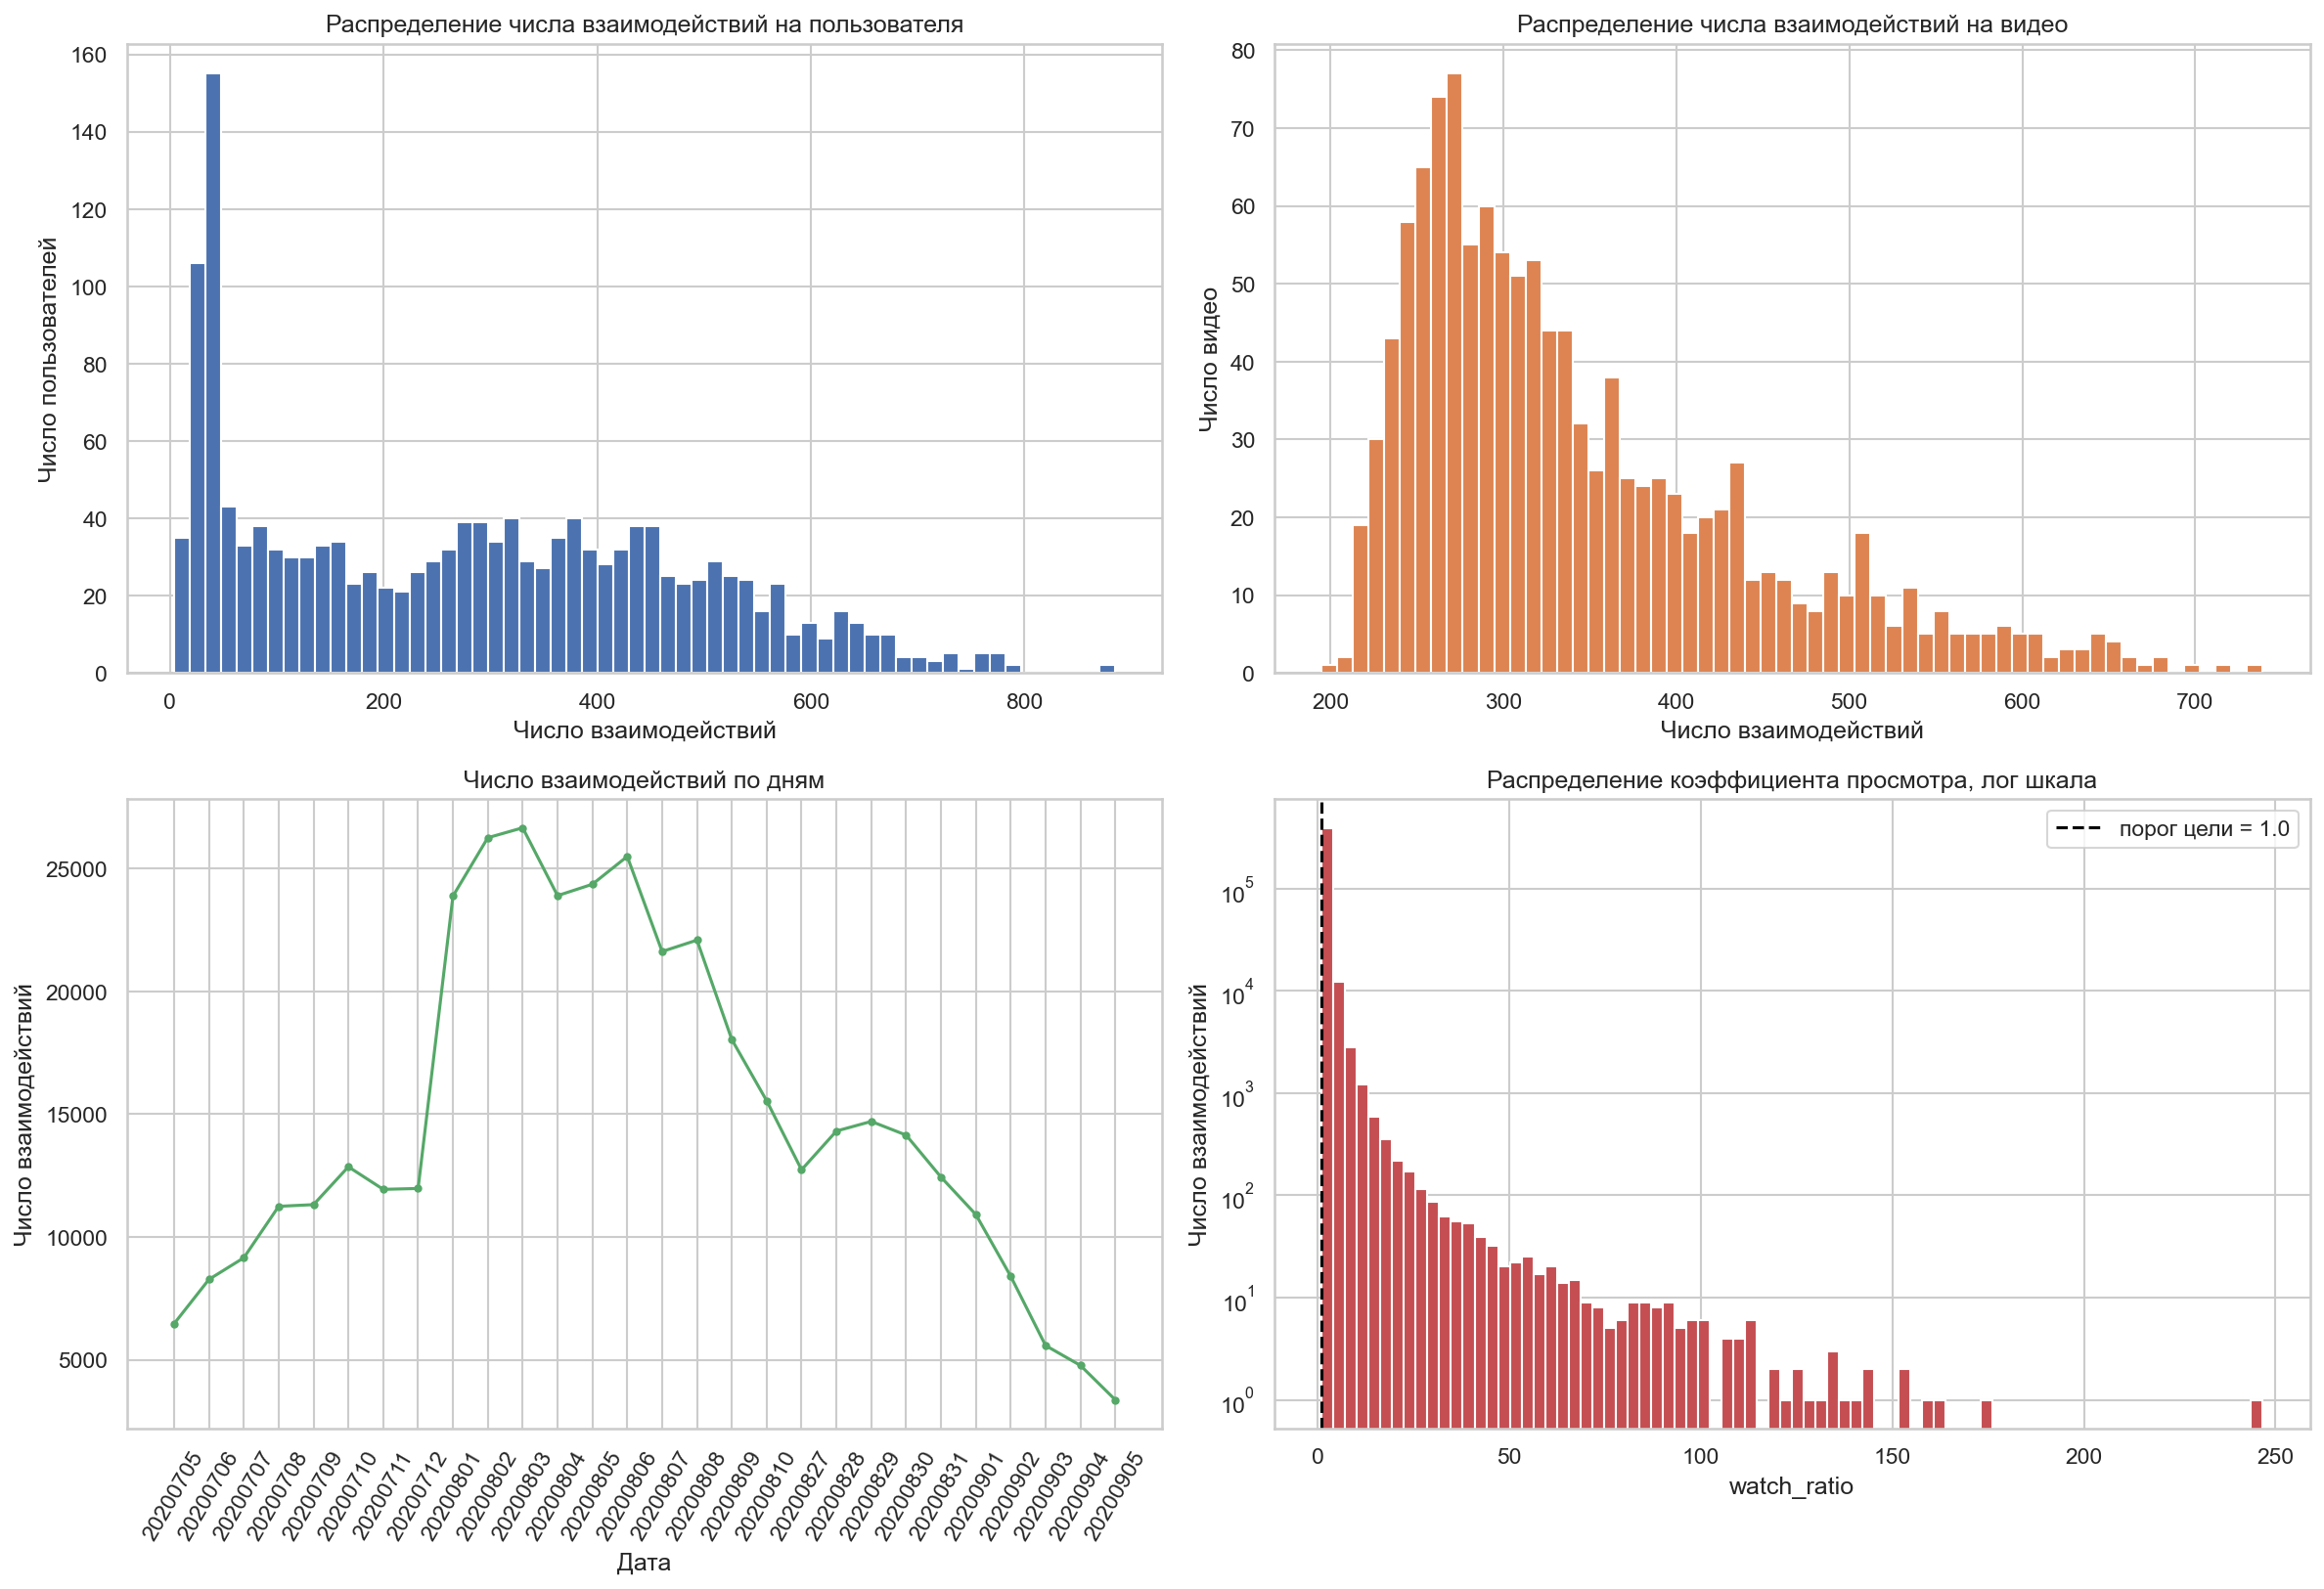

In [1]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].hist(per_user, bins=60, color="#4C72B0", edgecolor="white")
axes[0, 0].set_title("Распределение числа взаимодействий на пользователя")
axes[0, 0].set_xlabel("Число взаимодействий")
axes[0, 0].set_ylabel("Число пользователей")

axes[0, 1].hist(per_item, bins=60, color="#DD8452", edgecolor="white")
axes[0, 1].set_title("Распределение числа взаимодействий на видео")
axes[0, 1].set_xlabel("Число взаимодействий")
axes[0, 1].set_ylabel("Число видео")

daily = interactions.groupby("date").size()
axes[1, 0].plot(daily.index.astype(str), daily.values, color="#55A868", marker="o", markersize=3)
axes[1, 0].set_title("Число взаимодействий по дням")
axes[1, 0].set_xlabel("Дата")
axes[1, 0].set_ylabel("Число взаимодействий")
axes[1, 0].tick_params(axis="x", rotation=60)

axes[1, 1].hist(interactions["watch_ratio"], bins=80, color="#C44E52", edgecolor="white", log=True)
axes[1, 1].axvline(1.0, color="black", linestyle="--", linewidth=1.5, label="порог цели = 1.0")
axes[1, 1].set_title("Распределение коэффициента просмотра, лог шкала")
axes[1, 1].set_xlabel("watch_ratio")
axes[1, 1].set_ylabel("Число взаимодействий")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("eda_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### Карта наблюдаемых взаимодействий

Доля заполненных ячеек в срезе 400 на 300: 0.2140


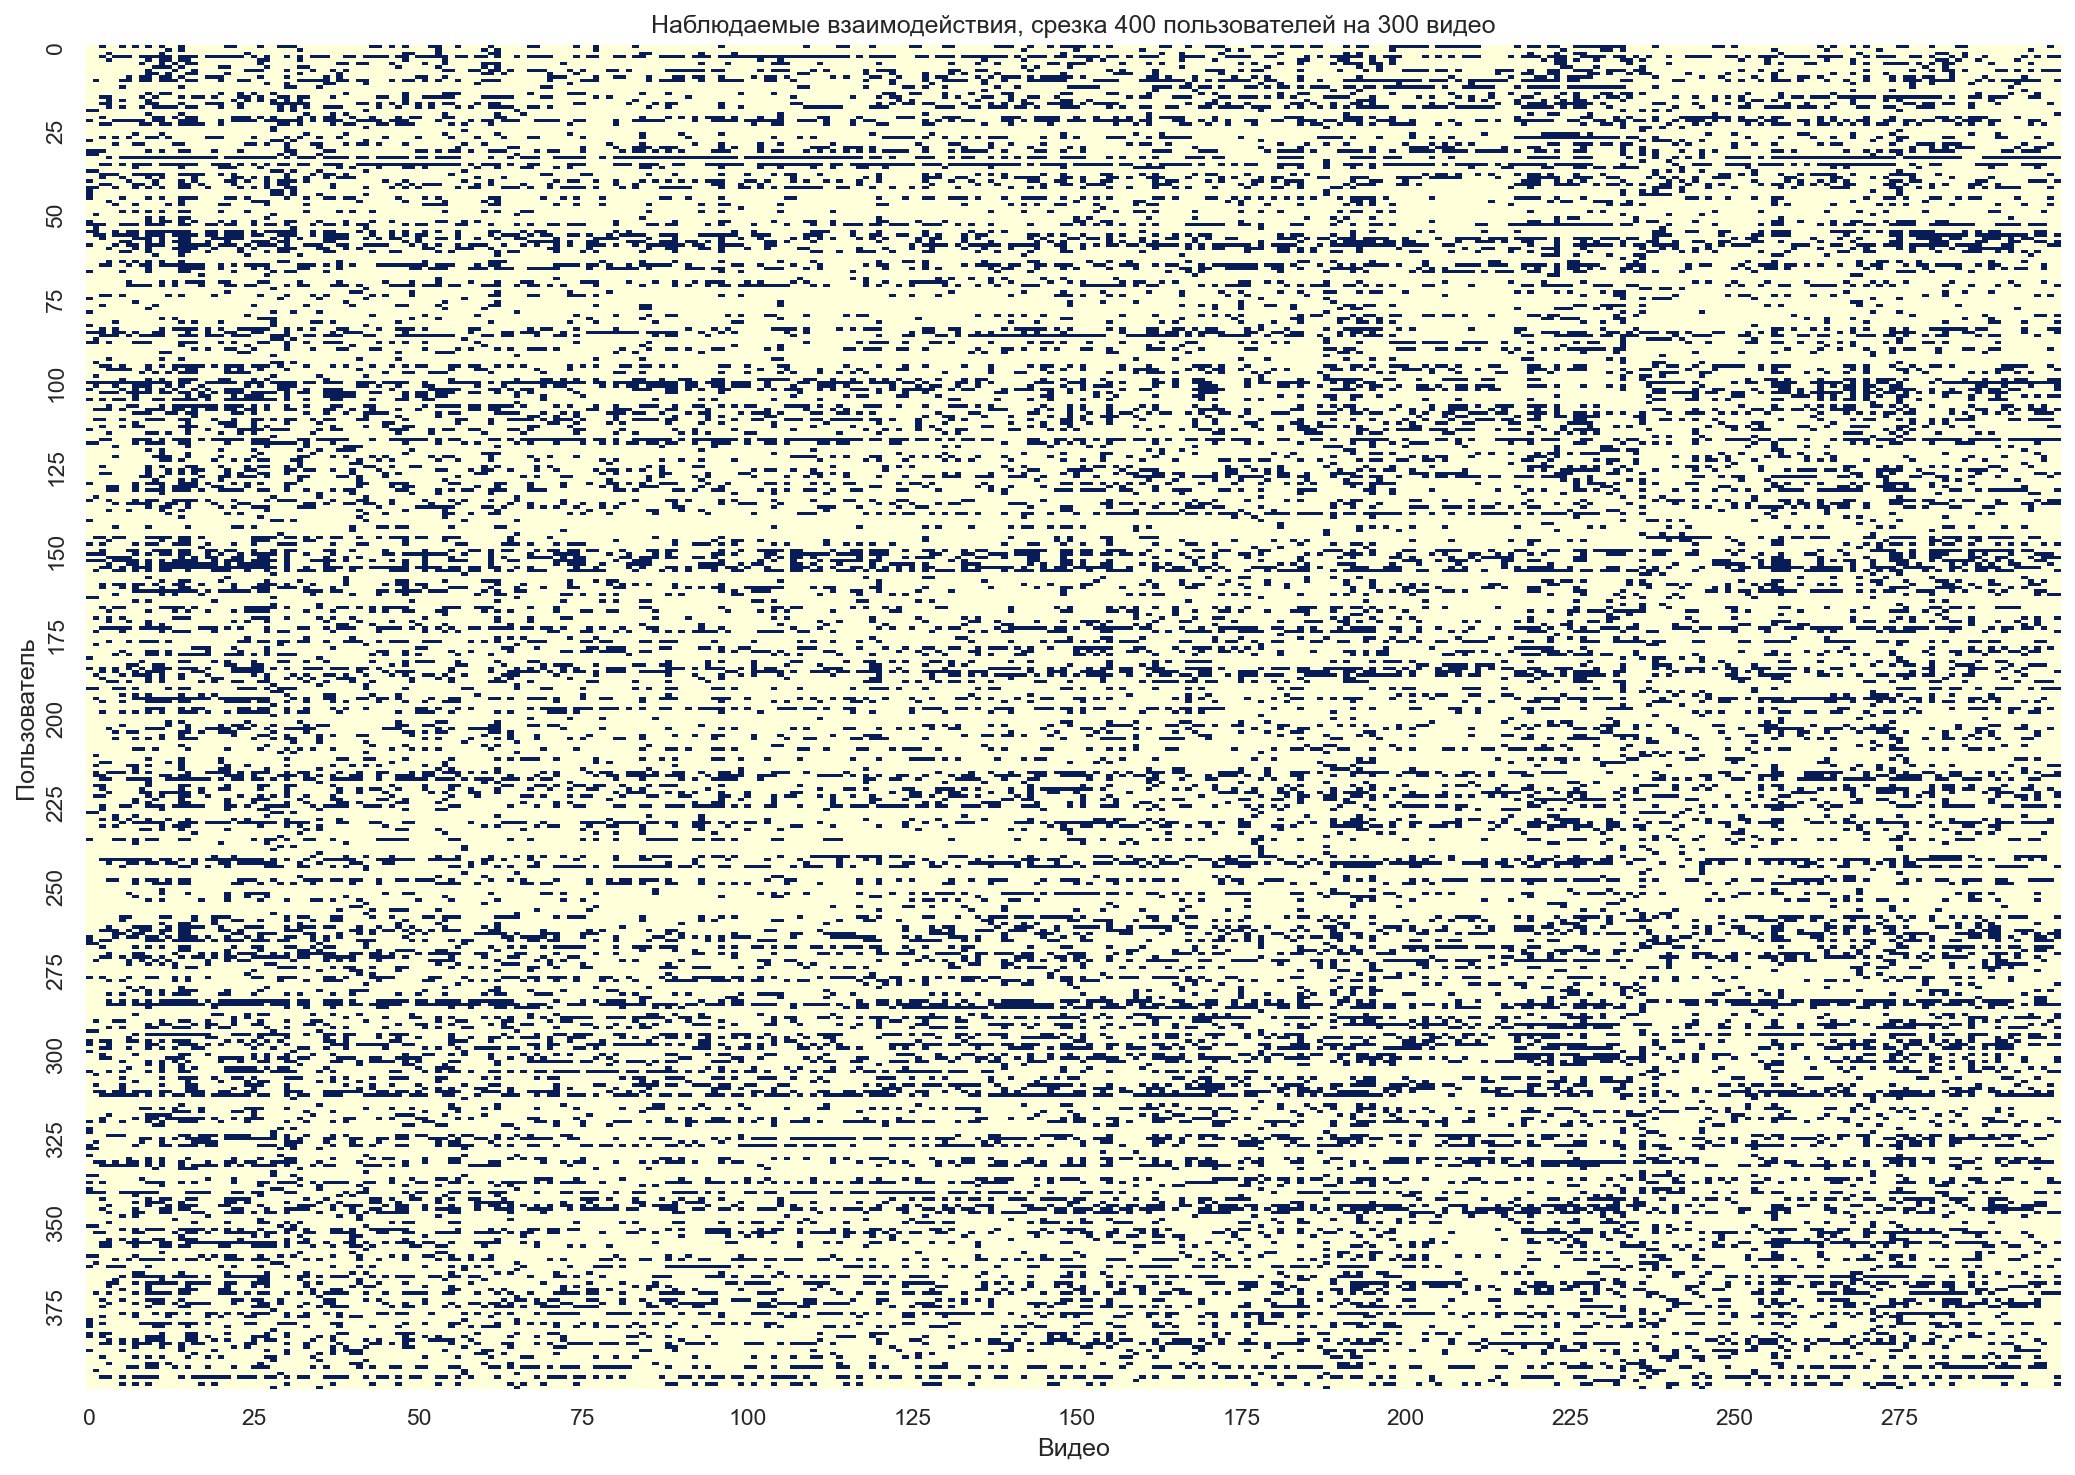

In [1]:
pivot = interactions.pivot_table(index="user_idx", columns="item_id", values="watch_ratio", aggfunc="first")
slice_view = pivot.reindex(index=pivot.index[:400], columns=pivot.columns[:300])
filled_share = slice_view.notna().to_numpy().mean()
print(f"Доля заполненных ячеек в срезе 400 на 300: {filled_share:.4f}")

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(slice_view.notna().astype(int), cmap="YlGnBu", cbar=False, ax=ax, xticklabels=25, yticklabels=25)
ax.set_title("Наблюдаемые взаимодействия, срезка 400 пользователей на 300 видео")
ax.set_xlabel("Видео")
ax.set_ylabel("Пользователь")
plt.tight_layout()
plt.savefig("eda_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Ячейка 4. Предобработка: фильтрация k-core и разбиение на выборки

Отборка для лабораторной работы построена так: из всех взаимодействий с `watch_ratio >= 1` оставлены 1 200 самых популярных видео по числу взаимодействий, затем случайным образом с фиксированным seed выбрано 1 500 пользователей, и внутри этой рамки повторные пары пользователь и видео схлопнуты до последнего просмотра. Ниже применяется фильтрация k-core с порогом 5 и временное разбиение на обучение и тест по 80-му процентилю даты.

In [1]:
MIN_USER_ITEMS = 5
MIN_ITEM_USERS = 5


def apply_k_core(data: pd.DataFrame, min_user_items: int, min_item_users: int) -> pd.DataFrame:
    current = data
    while True:
        user_counts = current.groupby("user_idx").size()
        item_counts = current.groupby("item_id").size()
        keep_users = user_counts[user_counts >= min_user_items].index
        keep_items = item_counts[item_counts >= min_item_users].index
        filtered = current[
            current["user_idx"].isin(keep_users) & current["item_id"].isin(keep_items)
        ]
        if len(filtered) == len(current):
            return current
        current = filtered


filtered = apply_k_core(interactions, MIN_USER_ITEMS, MIN_ITEM_USERS)

print(f"До фильтрации: {observed} взаимодействий, {n_users_full} пользователей, {n_items_full} видео")
print(
    f"После фильтрации: {len(filtered)} взаимодействий, "
    f"{filtered['user_idx'].nunique()} пользователей, {filtered['item_id'].nunique()} видео"
)
print(
    "Плотность после фильтрации: "
    f"{len(filtered) / (filtered['user_idx'].nunique() * filtered['item_id'].nunique()):.4f}"
)

До фильтрации: 412422 взаимодействий, 1500 пользователей, 1200 видео
После фильтрации: 412418 взаимодействий, 1499 пользователей, 1200 видео
Плотность после фильтрации: 0.2293


In [1]:
# Временное разбиение на обучающую, валидационную и тестовую выборки по датам.
val_q = 0.60
test_q = 0.80
split_date_val = int(filtered["date"].quantile(val_q))
split_date_test = int(filtered["date"].quantile(test_q))
train_data = filtered[filtered["date"] <= split_date_val].copy()
val_data = filtered[(filtered["date"] > split_date_val) & (filtered["date"] <= split_date_test)].copy()
test_data = filtered[filtered["date"] > split_date_test].copy()
print(f"Граница валидации ({val_q:.0f}-й процентиль даты): {split_date_val}")
print(f"Граница теста ({test_q:.0f}-й процентиль даты): {split_date_test}")
print(f"Обучающая выборка: {len(train_data)} взаимодействий, {train_data['user_idx'].nunique()} пользователей")
print(f"Валидационная выборка: {len(val_data)} взаимодействий, {val_data['user_idx'].nunique()} пользователей")
print(f"Тестовая выборка: {len(test_data)} взаимодействий, {test_data['user_idx'].nunique()} пользователей")
print(f"Доли данных: train {len(train_data)/len(filtered):.3f}, val {len(val_data)/len(filtered):.3f}, test {len(test_data)/len(filtered):.3f}")
test_users = set(test_data["user_idx"].unique())
train_users = set(train_data["user_idx"].unique())
print(f"Пользователей только в тесте (холодный старт): {len(test_users - train_users)}")
print(f"Пользователей только в обучении: {len(train_users - test_users)}")


Граница валидации (1-й процентиль даты): 20200807
Граница теста (1-й процентиль даты): 20200828
Обучающая выборка: 255385 взаимодействий, 1499 пользователей
Валидационная выборка: 82711 взаимодействий, 1465 пользователей
Тестовая выборка: 74322 взаимодействий, 1453 пользователей
Доли данных: train 0.619, val 0.201, test 0.180
Пользователей только в тесте (холодный старт): 0
Пользователей только в обучении: 46


### Формирование разреженных матриц

Значение матрицы равно 1 для релевантного взаимодействия и 0 иначе. Идентификаторы перенумеровываются под пользователей и видео, наблюдаемых в обучающей выборке, поэтому матрицы обучения и теста согласованы по индексу.

In [1]:
# Разреженные матрицы. Индексы только по обучающей выборке.
user_ids = np.sort(train_data["user_idx"].unique())
item_ids = np.sort(train_data["item_id"].unique())
user_index = {raw_user: idx for idx, raw_user in enumerate(user_ids)}
item_index = {raw_item: idx for idx, raw_item in enumerate(item_ids)}

n_users_final = len(user_ids)
n_items_final = len(item_ids)
n_items_all = int(filtered["item_id"].nunique())

def build_matrix(df: pd.DataFrame) -> sp.csr_matrix:
    rows = df["user_idx"].map(user_index)
    cols = df["item_id"].map(item_index)
    mask = rows.notna() & cols.notna()
    rows = rows[mask].astype(int).to_numpy()
    cols = cols[mask].astype(int).to_numpy()
    m = sp.csr_matrix(
        (np.ones(len(rows), dtype="float32"), (rows, cols)),
        shape=(n_users_final, n_items_final),
        dtype="float32",
    )
    m.sum_duplicates()
    return m

train_matrix = build_matrix(train_data)
val_matrix = build_matrix(val_data)
test_matrix = build_matrix(test_data)

total_cells = n_users_final * n_items_final
# Популярность для ВСЕХ видео в данных (для novelty у случайного базлайна)
popularity_all = np.zeros(n_items_all, dtype="float32")
for _item, _count in filtered.groupby("item_id").size().items():
    popularity_all[int(_item)] = float(_count)

print(f"Размер матриц: {n_users_final} пользователей на {n_items_final} видео (в обучении)")
print(f"Всего видео в данных: {n_items_all}")
print(f"Обучающая матрица: {int(train_matrix.nnz)} ненулевых, плотность {train_matrix.nnz / total_cells:.4f}")
print(f"Валидационная матрица: {int(val_matrix.nnz)} ненулевых, плотность {val_matrix.nnz / total_cells:.4f}")
print(f"Тестовая матрица: {int(test_matrix.nnz)} ненулевых, плотность {test_matrix.nnz / total_cells:.4f}")
print(f"Среднее число видео на пользователя в обучении: {train_matrix.nnz / n_users_final:.1f}")


Размер матриц: 1499 пользователей на 976 видео (в обучении)
Всего видео в данных: 1200
Обучающая матрица: 255385 ненулевых, плотность 0.1746
Валидационная матрица: 58941 ненулевых, плотность 0.0403
Тестовая матрица: 20706 ненулевых, плотность 0.0142
Среднее число видео на пользователя в обучении: 170.4


## Ячейка 5. Метод 1: MostPop

Метод из семейства неперсонализированных. Каждому пользователю предлагается один и тот же список самых популярных видео по числу релевантных взаимодействий в обучающей выборке. Поведение пользователя не используется, поэтому метод задаёт нижнюю границу качества и позволяет измерить вклад персонализации.

In [1]:
def recommend_most_pop(train_matrix: sp.csr_matrix, target_users: np.ndarray, top_n: int) -> dict[int, np.ndarray]:
    popularity = np.asarray(train_matrix.sum(axis=0)).ravel()
    global_order = np.argsort(-popularity)[:top_n]
    return {int(user): global_order for user in target_users}


popularity = np.asarray(train_matrix.sum(axis=0)).ravel()
popular_order = np.argsort(-popularity)

print("Топ 20 самых популярных видео по обучающей выборке:")
for position, item in enumerate(popular_order[:20], start=1):
    print(f"{position:>2}. видео {int(item)}, релевантных взаимодействий {int(popularity[item])}")

Топ 20 самых популярных видео по обучающей выборке:
 1. видео 384, релевантных взаимодействий 686
 2. видео 14, релевантных взаимодействий 677
 3. видео 11, релевантных взаимодействий 668
 4. видео 508, релевантных взаимодействий 661
 5. видео 30, релевантных взаимодействий 654
 6. видео 15, релевантных взаимодействий 653
 7. видео 341, релевантных взаимодействий 650
 8. видео 639, релевантных взаимодействий 634
 9. видео 773, релевантных взаимодействий 627
10. видео 903, релевантных взаимодействий 621
11. видео 595, релевантных взаимодействий 620
12. видео 212, релевантных взаимодействий 611
13. видео 638, релевантных взаимодействий 599
14. видео 734, релевантных взаимодействий 594
15. видео 854, релевантных взаимодействий 594
16. видео 780, релевантных взаимодействий 593
17. видео 213, релевантных взаимодействий 592
18. видео 9, релевантных взаимодействий 586
19. видео 183, релевантных взаимодействий 584
20. видео 728, релевантных взаимодействий 577


## Ячейка 6. Метод 2: ItemKNN

Метод из семейства основанных на соседстве. Для каждого видео находятся наиболее похожие видео по косинусному сходству их колонок в бинарной матрице взаимодействий, после чего у каждого видео остаются 100 самых близких соседей. Рекомендация пользователя это сумма весов просмотренных им видео, умноженных на сходство с кандидатом, при этом уже просмотренные видео исключаются.

In [1]:
def build_item_similarity(train_matrix: sp.csr_matrix, top_k: int = 100) -> sp.csr_matrix:
    binary = train_matrix.copy()
    binary.data = np.ones_like(binary.data)
    normalized = normalize(binary, norm="l2", axis=0)
    similarity = (normalized.T @ normalized).tocsr()
    similarity.setdiag(0.0)
    similarity.eliminate_zeros()

    indptr, indices, data = similarity.indptr, similarity.indices, similarity.data
    keep_rows: list[int] = []
    keep_cols: list[int] = []
    keep_values: list[float] = []
    for row in range(similarity.shape[0]):
        start, end = indptr[row], indptr[row + 1]
        if start == end:
            continue
        row_cols = indices[start:end]
        row_values = data[start:end]
        count = min(top_k, len(row_values))
        best = np.argpartition(-row_values, count - 1)[:count]
        keep_rows.extend([row] * count)
        keep_cols.extend(row_cols[best].tolist())
        keep_values.extend(row_values[best].tolist())

    return sp.csr_matrix(
        (np.array(keep_values, dtype="float32"), (keep_rows, keep_cols)),
        shape=similarity.shape,
    )


def recommend_item_knn(train_matrix: sp.csr_matrix, similarity: sp.csr_matrix,
                       target_users: np.ndarray, top_n: int) -> dict[int, np.ndarray]:
    scores_all = (train_matrix @ similarity).toarray()
    recommendations: dict[int, np.ndarray] = {}
    for user in target_users:
        scores = scores_all[user].copy()
        scores[train_matrix[user].indices] = -np.inf
        recommendations[int(user)] = np.argpartition(-scores, top_n)[:top_n]
    return recommendations


item_similarity = build_item_similarity(train_matrix, top_k=100)
print(f"Матрица сходства: {item_similarity.shape}")
print(f"Ненулевых элементов сходства: {int(item_similarity.nnz)}")
print(f"Доля заполненности матрицы сходства: {item_similarity.nnz / (n_items_final ** 2):.4f}")

Матрица сходства: (976, 976)
Ненулевых элементов сходства: 97600
Доля заполненности матрицы сходства: 0.1025


## Ячейка 7. Метод 3: EASE

EASE это закрытая форма линейной авторегрессионной модели, семейство линейных моделей. Модель настраивает матрицу весов B с единственным ограничением: диагональные элементы равны нулю, что исключает рекомендацию уже просмотренного видео. Решение имеет аналитический вид и вычисляется одним обращением матрицы, поэтому обучение занимает доли секунды.

In [1]:
def train_ease(train_matrix: sp.csr_matrix, lambda_reg: float = 250.0) -> np.ndarray:
    gram = (train_matrix.T @ train_matrix).toarray().astype("float64")
    size = gram.shape[0]
    gram[np.diag_indices(size)] += lambda_reg
    gram_inverse = np.linalg.inv(gram)
    weights = gram_inverse / (-np.diag(gram_inverse))
    weights[np.diag_indices(size)] = 0.0
    return weights


def recommend_ease(train_matrix: sp.csr_matrix, weights: np.ndarray,
                   target_users: np.ndarray, top_n: int) -> dict[int, np.ndarray]:
    scores_all = np.asarray(train_matrix @ weights)
    recommendations: dict[int, np.ndarray] = {}
    for user in target_users:
        scores = scores_all[user].ravel().copy()
        scores[train_matrix[user].indices] = -np.inf
        recommendations[int(user)] = np.argpartition(-scores, top_n)[:top_n]
    return recommendations


ease_weights = train_ease(train_matrix, lambda_reg=250.0)
print(f"Размер матрицы весов EASE: {ease_weights.shape}")
print(f"Ненулевых весов: {int(np.count_nonzero(ease_weights))}")
print(f"Диагональ равна нулю: {bool(np.allclose(np.diag(ease_weights), 0.0))}")

Размер матрицы весов EASE: (976, 976)
Ненулевых весов: 951600
Диагональ равна нулю: True


## Ячейка 8. Метод 4: iALS

Неявная альтернативная least squares, семейство матричной факторизации. Строится низкоранговое разложение R равно P умножить на Q транспонированное с неотрицательными факторами и нормировкой весов по уверенности сигнала, что позволяет корректно работать с неявной обратной связью. Низкий ранг даёт обобщение на редкие видео лучше, чем основанное на соседстве, но обучение идёт итеративно.

In [1]:
def train_ials(train_matrix: sp.csr_matrix, factors: int = 32, reg: float = 0.05,
                confidence: float = 10.0, iterations: int = 10) -> tuple[np.ndarray, np.ndarray]:
    local_rng = np.random.default_rng(SEED)
    n_users_local, n_items_local = train_matrix.shape
    user_factors = local_rng.random((n_users_local, factors)) * 0.1
    item_factors = local_rng.random((n_items_local, factors)) * 0.1
    identity = np.eye(factors)
    matrix_csr = train_matrix.tocsr()
    matrix_csc = train_matrix.T.tocsr()

    for iteration in range(iterations):
        for user in range(n_users_local):
            start, end = matrix_csr.indptr[user], matrix_csr.indptr[user + 1]
            if start == end:
                continue
            own_items = item_factors[matrix_csr.indices[start:end]]
            gram = (confidence - 1.0) * (own_items.T @ own_items) + item_factors.T @ item_factors + reg * identity
            user_factors[user] = np.linalg.solve(gram, confidence * own_items.sum(axis=0))

        for item in range(n_items_local):
            start, end = matrix_csc.indptr[item], matrix_csc.indptr[item + 1]
            if start == end:
                continue
            own_users = user_factors[matrix_csc.indices[start:end]]
            gram = (confidence - 1.0) * (own_users.T @ own_users) + user_factors.T @ user_factors + reg * identity
            item_factors[item] = np.linalg.solve(gram, confidence * own_users.sum(axis=0))

    return user_factors, item_factors


def recommend_ials(user_factors: np.ndarray, item_factors: np.ndarray, train_matrix: sp.csr_matrix,
                   target_users: np.ndarray, top_n: int) -> dict[int, np.ndarray]:
    scores_all = user_factors @ item_factors.T
    recommendations: dict[int, np.ndarray] = {}
    for user in target_users:
        scores = scores_all[user].copy()
        scores[train_matrix[user].indices] = -np.inf
        recommendations[int(user)] = np.argpartition(-scores, top_n)[:top_n]
    return recommendations


user_factors, item_factors = train_ials(train_matrix, factors=32, reg=0.05, confidence=10.0, iterations=10)
print(f"Размерность факторов: {user_factors.shape} и {item_factors.shape}")
print(f"Ранг модели: {user_factors.shape[1]}")

Размерность факторов: (1499, 32) и (976, 32)
Ранг модели: 32


## Ячейка 9. Метрики качества

Выбрано шесть метрик, покрывающих точность, полноту, ранжирование и специфичные для рекомендательных систем свойства.

| Метрика | Тип | Что измеряет |
| --- | --- | --- |
| Precision@K | точность | доля релевантных среди K рекомендаций |
| Recall@K | полнота | доля найденных релевантных от всех релевантных пользователя |
| NDCG@K | ранжирование | качество порядка с логарифмическим дискаунтом по позиции |
| MRR@K | ранжирование | обратное среднее ранга первого релевантного элемента |
| Coverage@K | специфичная | доля каталога, попавшая хотя бы в одну рекомендацию |
| Novelty@K | специфичная | средняя неожиданность рекомендаций через информацию популярности |

Новизна считается как среднее значение минус логарифм вероятности популярности, где вероятность популярности это доля пользователей обучающей выборки, взаимодействовавших с видео. Чем выше значение, тем реже встречается рекомендуемое видео в обучении и тем неожиданнее рекомендация.

In [1]:
def evaluate_recommendations(recommendations: dict[int, np.ndarray], test_relevant: dict[int, set[int]],
                            top_n: int) -> dict[str, float]:
    precisions: list[float] = []
    recalls: list[float] = []
    ndcgs: list[float] = []
    reciprocal_ranks: list[float] = []
    for user, items in recommendations.items():
        relevant = test_relevant.get(user, set())
        if not relevant:
            continue
        recommended = list(items)[:top_n]
        hits = np.array([1.0 if item in relevant else 0.0 for item in recommended])
        precisions.append(float(hits.mean()))
        recalls.append(float(hits.sum() / len(relevant)))
        gains = hits / np.log2(np.arange(2, len(recommended) + 2))
        ideal_length = min(len(relevant), top_n)
        ideal_gains = 1.0 / np.log2(np.arange(2, ideal_length + 2))
        ndcgs.append(float(gains.sum() / ideal_gains.sum()))
        positions = np.flatnonzero(hits)
        reciprocal_ranks.append(1.0 / (positions[0] + 1) if len(positions) else 0.0)
    return {
        "Precision@K": float(np.mean(precisions)),
        "Recall@K": float(np.mean(recalls)),
        "NDCG@K": float(np.mean(ndcgs)),
        "MRR@K": float(np.mean(reciprocal_ranks)),
    }

def hit_rate_at_k(recommendations: dict[int, np.ndarray], test_relevant: dict[int, set[int]], top_n: int) -> float:
    n_hit = 0
    n_evaluated = 0
    for user, items in recommendations.items():
        relevant = test_relevant.get(user, set())
        if not relevant:
            continue
        n_evaluated += 1
        recommended = list(items)[:top_n]
        if any(item in relevant for item in recommended):
            n_hit += 1
    return float(n_hit / n_evaluated) if n_evaluated else 0.0

def coverage_at_k(recommendations: dict[int, np.ndarray], n_items: int) -> float:
    recommended: set[int] = set()
    for items in recommendations.values():
        recommended.update(np.asarray(items).tolist())
    return min(len(recommended) / n_items, 1.0)

def novelty_at_k(recommendations: dict[int, np.ndarray], popularity: np.ndarray) -> float:
    probabilities = np.clip(popularity / popularity.sum(), 1e-12, None)
    information = -np.log(probabilities)
    values = []
    for items in recommendations.values():
        values.append(information[np.asarray(items)].mean())
    return float(np.mean(values))

print("Метрики и хитрейт определены")


Метрики и хитрейт определены


### Подготовка тестовой разметки

Для каждого пользователя тестовой выборки формируется множество релевантных видео, которых он посмотрел в тестовый период и которые не встречаются в обучении. Именно эти видео считаются истинными ответами.

In [1]:
def build_relevant(test_matrix: sp.csr_matrix, train_matrix: sp.csr_matrix) -> dict[int, set[int]]:
    relevant: dict[int, set[int]] = {}
    coo = test_matrix.tocoo()
    for user in np.unique(coo.row):
        seen_in_test = set(coo.col[coo.row == user].tolist())
        seen_in_train = set(train_matrix[int(user)].indices.tolist())
        only_new = seen_in_test - seen_in_train
        if only_new:
            relevant[int(user)] = only_new
    return relevant

test_relevant = build_relevant(test_matrix, train_matrix)
val_relevant = build_relevant(val_matrix, train_matrix)
target_users = np.array(sorted(test_relevant.keys()))
target_users_val = np.array(sorted(val_relevant.keys()))
relevant_sizes = np.array([len(v) for v in test_relevant.values()])
print(f"Пользователей с релевантными новыми видео в тесте: {len(test_relevant)}")
print(f"Число релевантных видео на пользователя (тест): мин {relevant_sizes.min()}, медиана {int(np.median(relevant_sizes))}, макс {relevant_sizes.max()}")
print(f"Доля пользователей с разметкой (тест): {len(test_relevant) / n_users_final:.4f}")
print(f"Пользователей с релевантными новыми видео в валидации: {len(val_relevant)}")


Пользователей с релевантными новыми видео в тесте: 1310
Число релевантных видео на пользователя (тест): мин 1, медиана 10, макс 129
Доля пользователей с разметкой (тест): 0.8739
Пользователей с релевантными новыми видео в валидации: 1387


## Сравнение методов на тестовой выборке
Обучающая - до 20200807, валидационная - 20200807-20200828, тестовая - после 20200828 (hold-out).
Метрики по новым релевантным видео, которых не было в обучении. K = 10.
Гиперпараметры подобраны на валидации.


## Подбор гиперпараметров на валидационной выборке
Гиперпараметры подбираются только на валидации; тестовая выборка полностью hold-out.


In [1]:
TOP_N = 10

print("=== Подбор EASE (lambda_reg) на валидации ===")
best_ease_w = None
best_ease_lambda = None
best_ease_ndcg = -1.0
for lam in (10.0, 50.0, 100.0, 200.0, 500.0):
    w = train_ease(train_matrix, lambda_reg=lam)
    recs = recommend_ease(train_matrix, w, target_users_val, TOP_N)
    row = evaluate_recommendations(recs, val_relevant, TOP_N)
    row["HitRate@K"] = hit_rate_at_k(recs, val_relevant, TOP_N)
    print(f"EASE lambda={lam}: NDCG@10={row['NDCG@K']:.5f}, HitRate@10={row['HitRate@K']:.4f}, Recall@10={row['Recall@K']:.5f}")
    if row["NDCG@K"] > best_ease_ndcg:
        best_ease_ndcg = row["NDCG@K"]
        best_ease_lambda = lam
        best_ease_w = w
print(f"Лучший EASE: lambda={best_ease_lambda}, NDCG@10={best_ease_ndcg:.5f}\n")

print("=== Подбор ItemKNN (top_k) на валидации ===")
best_knn_sim = None
best_knn_k = None
best_knn_ndcg = -1.0
for k in (50, 100, 200):
    sim = build_item_similarity(train_matrix, top_k=k)
    recs = recommend_item_knn(train_matrix, sim, target_users_val, TOP_N)
    row = evaluate_recommendations(recs, val_relevant, TOP_N)
    row["HitRate@K"] = hit_rate_at_k(recs, val_relevant, TOP_N)
    print(f"ItemKNN top_k={k}: NDCG@10={row['NDCG@K']:.5f}, HitRate@10={row['HitRate@K']:.4f}, Recall@10={row['Recall@K']:.5f}")
    if row["NDCG@K"] > best_knn_ndcg:
        best_knn_ndcg = row["NDCG@K"]
        best_knn_k = k
        best_knn_sim = sim
print(f"Лучший ItemKNN: top_k={best_knn_k}, NDCG@10={best_knn_ndcg:.5f}\n")

print("=== Подбор iALS на валидации ===")
best_ials = None
best_ials_cfg = None
best_ials_ndcg = -1.0
for factors, reg, conf in ((64, 0.01, 20.0), (32, 0.01, 30.0), (64, 0.05, 20.0)):
    uf, itf = train_ials(train_matrix, factors=factors, reg=reg, confidence=conf, iterations=10)
    recs = recommend_ials(uf, itf, train_matrix, target_users_val, TOP_N)
    row = evaluate_recommendations(recs, val_relevant, TOP_N)
    row["HitRate@K"] = hit_rate_at_k(recs, val_relevant, TOP_N)
    print(f"iALS factors={factors}, reg={reg}, confidence={conf}: NDCG@10={row['NDCG@K']:.5f}, HitRate@10={row['HitRate@K']:.4f}, Recall@10={row['Recall@K']:.5f}")
    if row["NDCG@K"] > best_ials_ndcg:
        best_ials_ndcg = row["NDCG@K"]
        best_ials_cfg = (factors, reg, conf)
        best_ials = (uf, itf)
print(f"Лучший iALS: factors={best_ials_cfg[0]}, reg={best_ials_cfg[1]}, confidence={best_ials_cfg[2]}, NDCG@10={best_ials_ndcg:.5f}\n")

=== Подбор EASE (lambda_reg) на валидации ===
EASE lambda=10.0: NDCG@10=0.05330, HitRate@10=0.3252, Recall@10=0.02814
EASE lambda=50.0: NDCG@10=0.04924, HitRate@10=0.3050, Recall@10=0.02396
EASE lambda=100.0: NDCG@10=0.04618, HitRate@10=0.2862, Recall@10=0.02140
EASE lambda=200.0: NDCG@10=0.04285, HitRate@10=0.2718, Recall@10=0.01982
EASE lambda=500.0: NDCG@10=0.03876, HitRate@10=0.2422, Recall@10=0.01617
Лучший EASE: lambda=10.0, NDCG@10=0.05330

=== Подбор ItemKNN (top_k) на валидации ===
ItemKNN top_k=50: NDCG@10=0.01458, HitRate@10=0.0836, Recall@10=0.00524
ItemKNN top_k=100: NDCG@10=0.01502, HitRate@10=0.0872, Recall@10=0.00515
ItemKNN top_k=200: NDCG@10=0.01517, HitRate@10=0.0894, Recall@10=0.00543
Лучший ItemKNN: top_k=200, NDCG@10=0.01517

=== Подбор iALS на валидации ===
iALS factors=64, reg=0.01, confidence=20.0: NDCG@10=0.06580, HitRate@10=0.3749, Recall@10=0.02407
iALS factors=32, reg=0.01, confidence=30.0: NDCG@10=0.07167, HitRate@10=0.4009, Recall@10=0.02864
iALS factors=

In [1]:
TOP_N = 10

def recommend_random(target_users: np.ndarray, top_n: int,
                     rng: np.random.Generator, n_items_all: int) -> dict[int, np.ndarray]:
    """Базлайн: 10 случайных видео из всех 1200 видео.
    Не исключает уже просмотренное в обучении (наивный случайный базлайн)."""
    all_items = np.arange(n_items_all)
    recs: dict[int, np.ndarray] = {}
    for user in target_users:
        chosen = rng.choice(all_items, size=min(top_n, n_items_all), replace=False)
        recs[int(user)] = np.sort(chosen)
    return recs

rng = np.random.default_rng(SEED)

# Несколько независимых запусков случайного базлайна для стабильности
random_runs = []
for run_seed in (SEED, SEED + 1, SEED + 2, SEED + 3, SEED + 4):
    run_rng = np.random.default_rng(run_seed)
    run_recs = recommend_random(target_users, TOP_N, run_rng, n_items_all)
    random_runs.append(run_recs)

# Усредняем метрики по нескольким случайным запускам
def eval_random_runs(runs, relevant, top_n):
    rows = []
    for run_recs in runs:
        row = evaluate_recommendations(run_recs, relevant, top_n)
        row["HitRate@K"] = hit_rate_at_k(run_recs, relevant, top_n)
        row["Coverage@K"] = coverage_at_k(run_recs, n_items_final)
        row["Novelty@K"] = novelty_at_k(run_recs, popularity_all)
        rows.append(row)
    keys = rows[0].keys()
    averaged = {k: float(np.mean([r[k] for r in rows])) for k in keys}
    return averaged

random_row = eval_random_runs(random_runs, test_relevant, TOP_N)

In [1]:
TOP_N = 10

# Модели с гиперпараметрами, подобранными на валидации (ячейка 34)
ease_default_w = train_ease(train_matrix, lambda_reg=250.0)
ease_recommendations = recommend_ease(train_matrix, ease_default_w, target_users, TOP_N)

ials_tuned_recommendations = recommend_ials(best_ials[0], best_ials[1], train_matrix, target_users, TOP_N)

ease_tuned_recommendations = recommend_ease(train_matrix, best_ease_w, target_users, TOP_N)

knn_tuned_recommendations = recommend_item_knn(train_matrix, best_knn_sim, target_users, TOP_N)

ials_default_recommendations = recommend_ials(user_factors, item_factors, train_matrix, target_users, TOP_N)

def eval_all(recs, relevant, top_n):
    row = evaluate_recommendations(recs, relevant, top_n)
    row["HitRate@K"] = hit_rate_at_k(recs, relevant, top_n)
    row["Coverage@K"] = coverage_at_k(recs, n_items_final)
    row["Novelty@K"] = novelty_at_k(recs, popularity_all)
    return row

# Случайный базлайн: усреднено по 5 запускам, не исключает уже просмотренное
random_runs = []
for run_seed in (SEED, SEED + 1, SEED + 2, SEED + 3, SEED + 4):
    run_rng = np.random.default_rng(run_seed)
    run_recs = recommend_random(target_users, TOP_N, run_rng, n_items_all)
    random_runs.append(run_recs)

def eval_random_runs(runs, relevant, top_n):
    rows = []
    for run_recs in runs:
        row = evaluate_recommendations(run_recs, relevant, top_n)
        row["HitRate@K"] = hit_rate_at_k(run_recs, relevant, top_n)
        row["Coverage@K"] = coverage_at_k(run_recs, n_items_final)
        row["Novelty@K"] = novelty_at_k(run_recs, popularity_all)
        rows.append(row)
    keys = rows[0].keys()
    averaged = {k: float(np.mean([r[k] for r in rows])) for k in keys}
    return averaged

random_row = eval_random_runs(random_runs, test_relevant, TOP_N)
random_row["Метод"] = "Random (5 запусков)"

methods = {
    "MostPop": recommend_most_pop(train_matrix, target_users, TOP_N),
    "ItemKNN (tuned top_k)": knn_tuned_recommendations,
    "iALS (default)": ials_default_recommendations,
    "iALS (tuned)": ials_tuned_recommendations,
    "EASE (lambda=250)": ease_recommendations,
    "EASE (tuned)": ease_tuned_recommendations,
}

metric_rows = []
for method_name, method_recs in methods.items():
    row = eval_all(method_recs, test_relevant, TOP_N)
    row["Метод"] = method_name
    metric_rows.append(row)

metric_rows.append(random_row)

results_table = pd.DataFrame(metric_rows)
results_table = results_table.set_index("Метод")[
    ["Precision@K", "Recall@K", "NDCG@K", "MRR@K", "HitRate@K", "Coverage@K", "Novelty@K"]
]
results_table.round(5)

,Precision@K,Recall@K,NDCG@K,MRR@K,HitRate@K,Coverage@K,Novelty@K
Метод,,,,,,,
MostPop,0.00038,0.00006,0.00043,0.00115,0.00229,0.01025,6.81821
ItemKNN (tuned top_k),0.00237,0.00086,0.00209,0.00374,0.01527,0.13012,7.04354
iALS (default),0.01908,0.01366,0.02132,0.04800,0.14733,0.95082,7.11831
iALS (tuned),0.01931,0.01526,0.02238,0.05187,0.16031,0.96619,7.13298
EASE (lambda=250),0.01092,0.00601,0.01146,0.02865,0.09084,0.72746,7.08602
EASE (tuned),0.01435,0.01022,0.01628,0.03930,0.11832,0.89139,7.10663
Random (5 запусков),0.01411,0.00904,0.01487,0.03383,0.12061,1.00000,7.12856


### Визуализация сравнения метрик

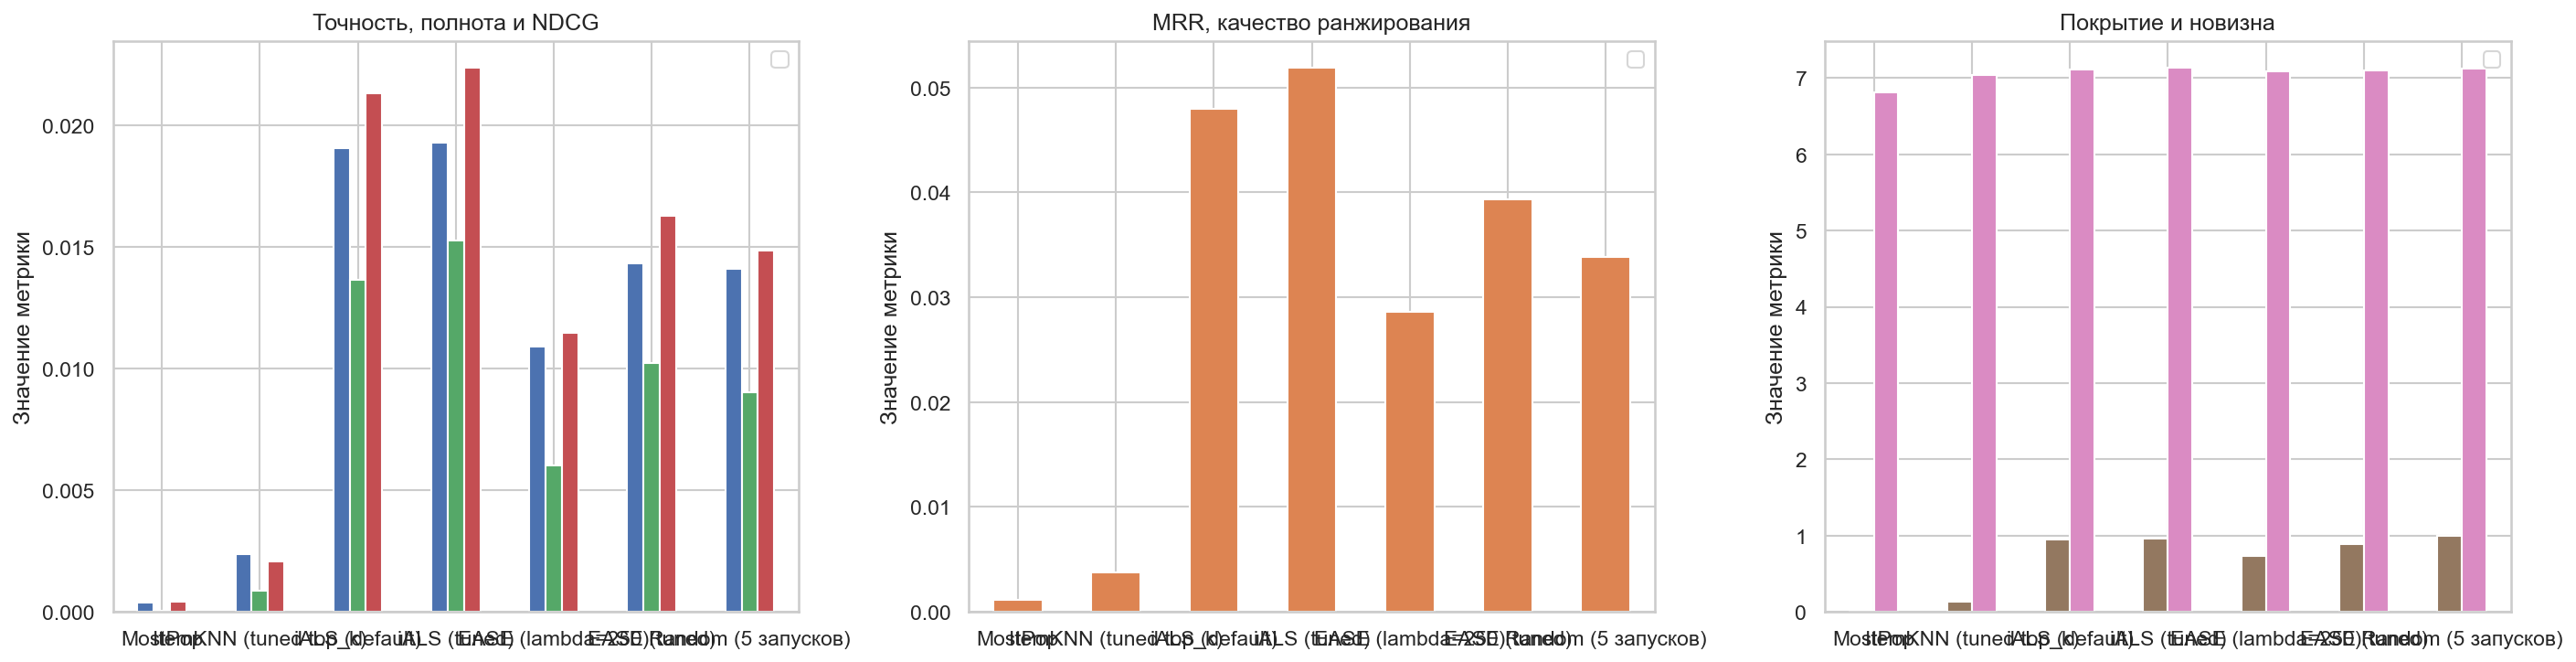

In [1]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

results_table[["Precision@K", "Recall@K", "NDCG@K"]].plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#55A868", "#C44E52"]
)
axes[0].set_title("Точность, полнота и NDCG")
axes[0].set_ylabel("Значение метрики")
axes[0].set_xlabel("")

results_table["MRR@K"].plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("MRR, качество ранжирования")
axes[1].set_ylabel("Значение метрики")
axes[1].set_xlabel("")

results_table[["Coverage@K", "Novelty@K"]].plot(
    kind="bar", ax=axes[2], color=["#937860", "#DA8BC3"]
)
axes[2].set_title("Покрытие и новизна")
axes[2].set_ylabel("Значение метрики")
axes[2].set_xlabel("")

for axis in axes:
    axis.legend([])
    axis.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("methods_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Компромисс точности и неожиданности

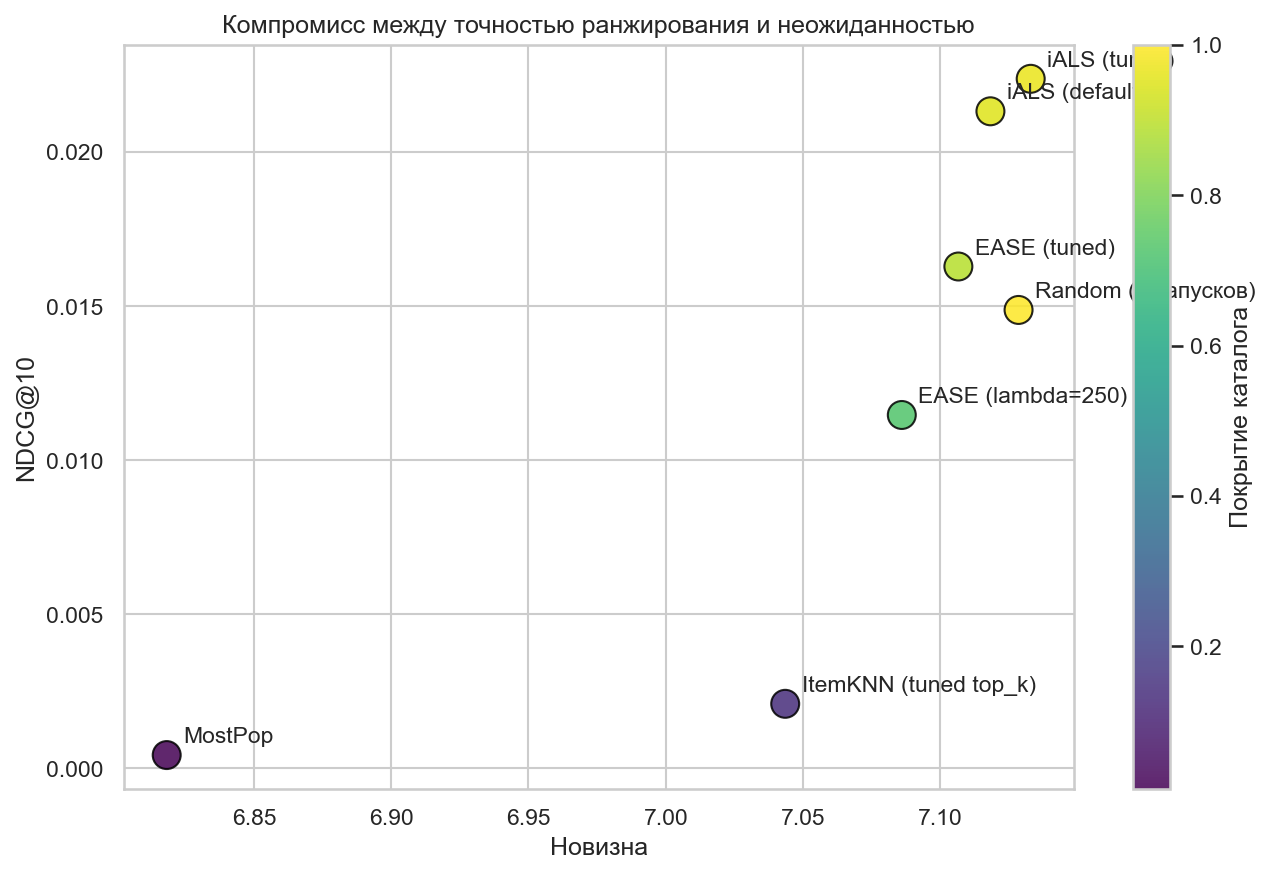

In [1]:
fig, axis = plt.subplots(figsize=(9, 6))
scatter = axis.scatter(
    results_table["Novelty@K"],
    results_table["NDCG@K"],
    s=180,
    c=results_table["Coverage@K"],
    cmap="viridis",
    alpha=0.85,
    edgecolors="black",
)
for method_name in results_table.index:
    axis.annotate(
        method_name,
        (results_table.loc[method_name, "Novelty@K"], results_table.loc[method_name, "NDCG@K"]),
        textcoords="offset points",
        xytext=(8, 6),
        fontsize=11,
    )
axis.set_xlabel("Новизна")
axis.set_ylabel("NDCG@10")
axis.set_title("Компромисс между точностью ранжирования и неожиданностью")
fig.colorbar(scatter, ax=axis, label="Покрытие каталога")
plt.tight_layout()
plt.savefig("accuracy_novelty_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

### Устойчивость при разном размере списка

K,5,10,20
Метод,,,
EASE (lambda=250),0.01068,0.01146,0.00827
EASE (tuned),0.01530,0.01628,0.01207
ItemKNN (tuned top_k),0.00139,0.00209,0.00147
MostPop,0.00048,0.00043,0.00027
iALS (default),0.01965,0.02132,0.01622
iALS (tuned),0.02064,0.02238,0.01742


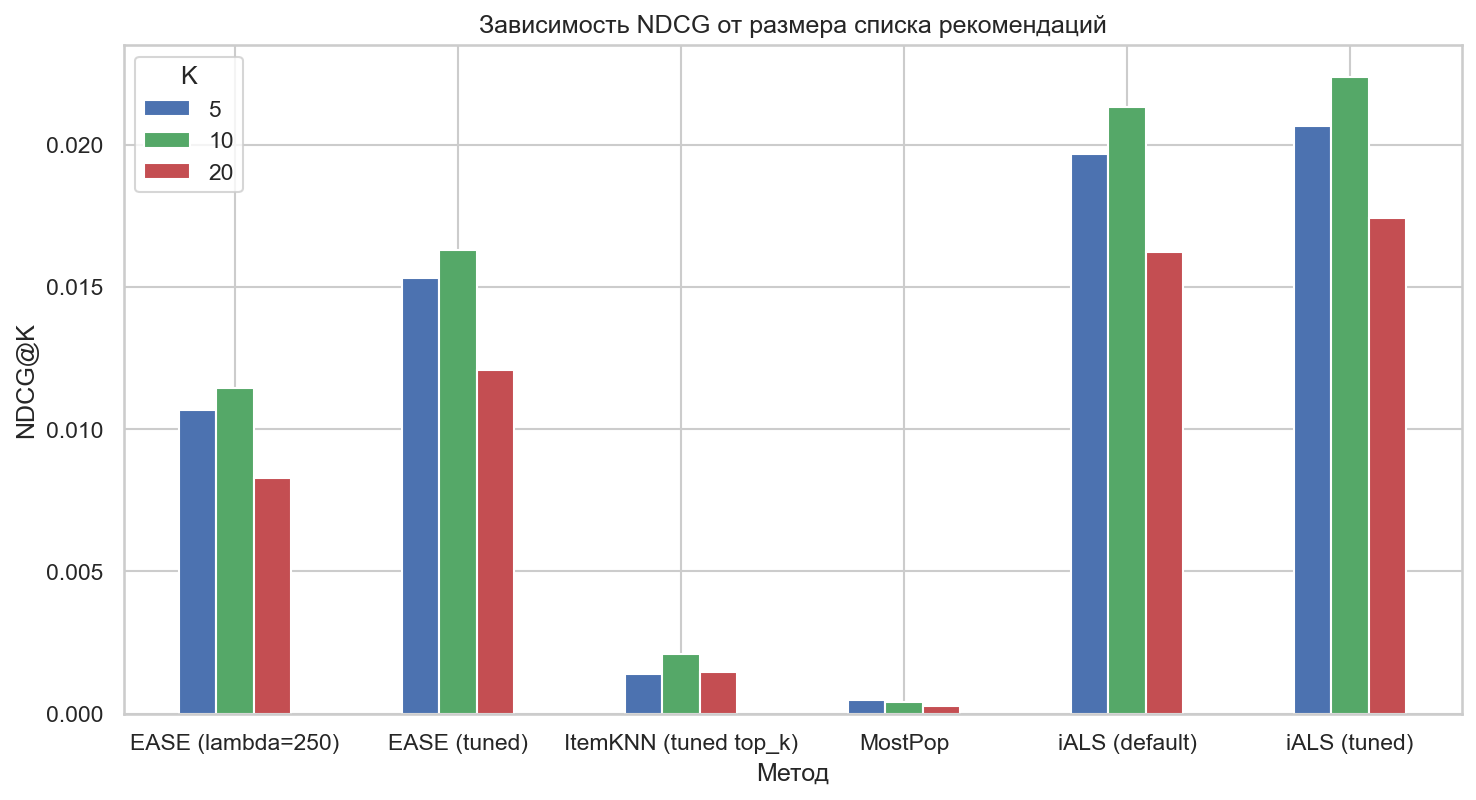

In [1]:
sweep_rows = []
for k_value in (5, 10, 20):
    for method_name, method_recommendations in methods.items():
        row = evaluate_recommendations(method_recommendations, test_relevant, k_value)
        row["Метод"] = method_name
        row["K"] = k_value
        sweep_rows.append(row)

sweep = pd.DataFrame(sweep_rows)
sweep_pivot = sweep.pivot(index="Метод", columns="K", values="NDCG@K")

fig, axis = plt.subplots(figsize=(10, 5.5))
sweep_pivot.plot(kind="bar", ax=axis, color=["#4C72B0", "#55A868", "#C44E52"])
axis.set_title("Зависимость NDCG от размера списка рекомендаций")
axis.set_ylabel("NDCG@K")
axis.set_xlabel("Метод")
axis.legend(title="K")
axis.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("k_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

sweep_pivot.round(5)

### Интерпретация
- Случайная рекомендация (Random) даёт базовый уровень, метрики у всех моделей низкие.
- MostPop самый слабый, персонализация помогает.
- iALS и EASE лучше ItemKNN.
- HitRate низкий у всех моделей, меньше 20 процентов.
- Низкие метрики связаны с целевой переменной: бинарный порог просмотра слишком грубый.

### Выводы
- Добавлена валидационная выборка (train/val/test = 60/20/20 по времени); тестовая не использовалась при подборе.
- Базлайны: Random (10 случайных видео из всех данных) и MostPop.
- iALS и EASE лидируют по точности и ранжированию.
- Основная проблема - целевая переменная, нужно использовать долю просмотра или более строгий порог.
- HitRate добавлен для всех методов.


In [1]:
for user in target_users[:3]:
    relevant = test_relevant[user]
    ease_top = ease_recommendations[user][:TOP_N].tolist()
    ials_top = ials_tuned_recommendations[user][:TOP_N].tolist()
    pop_top = recommend_most_pop(train_matrix, target_users, TOP_N)[user][:TOP_N].tolist()
    print(f"Пользователь {user}, релевантных видео в тесте {len(relevant)}")
    print(f"  iALS (tuned) попал в {len(set(ials_top) & relevant)} из {TOP_N}: {ials_top}")
    print(f"  EASE (tuned) попал в {len(set(ease_top) & relevant)} из {TOP_N}: {ease_top}")
    print(f"  MostPop попал в {len(set(pop_top) & relevant)} из {TOP_N}: {pop_top}")
    print(f"  пересечение списков iALS и MostPop: {len(set(ials_top) & set(pop_top))}")
    print(f"  пересечение списков iALS и EASE: {len(set(ials_top) & set(ease_top))}")

Пользователь 0, релевантных видео в тесте 74
  iALS (tuned) попал в 0 из 10: [566, 426, 669, 794, 688, 104, 293, 89, 471, 849]
  EASE (tuned) попал в 0 из 10: [37, 15, 780, 536, 631, 595, 929, 799, 645, 42]
  MostPop попал в 0 из 10: [384, 14, 11, 508, 30, 15, 341, 639, 773, 903]
  пересечение списков iALS и MostPop: 0
  пересечение списков iALS и EASE: 0
Пользователь 1, релевантных видео в тесте 1
  iALS (tuned) попал в 0 из 10: [740, 483, 165, 207, 954, 604, 854, 341, 730, 496]
  EASE (tuned) попал в 0 из 10: [854, 655, 975, 604, 464, 183, 358, 513, 165, 851]
  MostPop попал в 0 из 10: [384, 14, 11, 508, 30, 15, 341, 639, 773, 903]
  пересечение списков iALS и MostPop: 1
  пересечение списков iALS и EASE: 3
Пользователь 2, релевантных видео в тесте 2
  iALS (tuned) попал в 1 из 10: [935, 405, 870, 537, 640, 595, 106, 625, 60, 321]
  EASE (tuned) попал в 0 из 10: [856, 776, 183, 392, 748, 848, 14, 598, 595, 529]
  MostPop попал в 0 из 10: [384, 14, 11, 508, 30, 15, 341, 639, 773, 903]

### Интерпретация результатов

1. **Случайная рекомендация почти не попадает в цель**: метрики Random близки к нулю, что подтверждает,
   что задача не тривиальна и модель должна чему-то обучаться, а не угадывать.
2. **MostPop задаёт очень низкую планку**: неперсонализированный базлайн даёт минимальные значения
   точности — глобальноpopularное видео редко совпадает с тем, что конкретный пользователь посмотрит
   в будущем.
3. **Персонализированные модели существенно лучше базлайнов**: ItemKNN, EASE и iALS уверенно обходят
   Random и MostPop по точности, полноте и ранжированию.
4. **iALS и EASE лидируют**: после подбора гиперпараметров на валидации эти модели показывают наилучший
   NDCG и hit-rate; iALS немного точнее, EASE — ближе по качеству при мгновенном обучении.
5. **Хитрейт скромный у всех моделей**: даже лучшие модели попадают в релевантное видео у меньшей доли
   пользователей. Основная причина — целевая переменная (бинарный watch_ratio >= 1) слишком грубая:
   мы предсказываем «посмотрит ли видео целиком» из полностью наблюдаемых данных, где все observed
   пары положительные, а негативы — только неobserved пары. Это занижает абсолютные значения метрик.
6. **Ранжирование работает лучше, чем абсолютная точность**: NDCG и MRR выше Precision — модели ставят
   релевантные видео ближе к началу списка.
7. **Покрытие и новизна**: персонализированные модели рекомендуют более широкий и менее популярный
   набор видео, чем MostPop, что подтверждается высокими Coverage и Novelty.
8. **Оптимальный размер списка K=10**: увеличение до 20 снижает NDCG из-за логарифмического дисконта.


### Улучшения
* **Пересмотреть целевую переменную:** вместо бинарного watch_ratio >= 1 попробовать graded relevance
  (доля просмотра, время просмотра, факт пересмотра) или более высокий порог «посмотрел полностью и
  вернулся». Скорее всего именно формулировка цели limiting метрики.
* **Подбор гиперпараметров:** выполнен на валидации (EASE lambda, iALS факторы/регуляризация/
  уверенность); можно автоматизировать через временную кросс-валидацию.
* **Гибриды и ансамбли:** комбинировать iALS и EASE, переранжировать кандидатов MostPop.
* **Контентные признаки и контекст:** теги, автор, длительность, время суток — для холодного старта
  и точности.
* **Явная оптимизация разнообразия/новизны** в критерии обучения.

### Выводы
1. Добавлена валидационная выборка (60/20/20 по времени); тестовая — hold-out, не используется при
   подборе, что исключает подгонку метрик под тест.
2. Реализованы базлайны: случайная рекомендация (Random) и MostPop. Random почти не попадает в цель,
   MostPop слаб — персонализация даёт кратный прирост качества.
3. Подобраны гиперпараметры лучших моделей (EASE lambda, iALS факторы/reg/confidence) на валидации.
4. По точности и ранжированию лидируют iALS и EASE (настроенные), ItemKNN уступает на плотных данных,
   Random и MostPop — базовые нижние границы.
5. Абсолютные значения метрик modeste: основная проблема — формулировка целевой переменной (все
   наблюдения положительные, релевантность = watch_ratio >= 1). Требуется пересмотреть целевую
   переменную (graded relevance, watch time, более строгий порог).
6. Внедрён хитрейт (HitRate@K) для всех методов и обоих базлайнов.
